In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh

In [22]:
alpha = np.array([0.298073, 1.242567, 5.782948, 38.474970]) # alphas from the book

N = len(alpha) #number of basis functions

In [23]:
#we will gaussian function with l=0, so that the angular part is just a constant 
#also beacuse we are intrested in the ground state

# Create the matrices amul_{ij} = a_i * a_j and aplu_{ij} = a_i + a_j
amul = np.array(np.meshgrid(alpha, alpha)).prod(0)
aplu = np.array(np.meshgrid(alpha, alpha)).sum(0)

# Create the matrices aplumul_{ijml} = (a_i + a_m) * (a_j + a_l) and apluplu_{ijml} = a_i + a_j + a_m + a_l
aplumul = np.swapaxes(np.array(np.meshgrid(aplu, aplu)).prod(0).reshape((N, N, N, N)), 1, 2)
apluplu = np.array(np.meshgrid(aplu, aplu)).sum(0).reshape((N, N, N, N))

T = (3*np.pi**1.5)*amul/np.power(aplu,2.5) #kinetic energy
V = - 4*np.pi/(aplu) #helium nuclei coulomb energy
H = T+V #single particle matrix

S = np.power(np.pi / aplu, 1.5) #overlap matrix

Q = (2*np.pi**2.5)/(aplumul*np.power(apluplu,0.5))


In [24]:
#now the self consistent method: we fix C so that we can construnct F = H + C @ Q @ C and than proceed with a eigenvalue problem
maxiter = 100
tol = 1e-8

C = np.random.rand(len(alpha))
C /= np.sqrt(C @ S @ C)

for it in range(maxiter):
    F = H + np.einsum('prqs,r,s->pq', Q, C, C)
    eps, vecs = eigh(F, S)
    C_new = vecs[:, 0]
    C_new /= np.sqrt(C_new @ S @ C_new)
    if C_new[np.argmax(np.abs(C_new))] < 0:      # fix sign
        C_new = -C_new

    E = 2 * C_new @ H @ C_new + np.einsum('prqs,p,q,r,s->', Q, C_new, C_new, C_new, C_new)
    print(f"{it}: E = {E:.8f}, eps0 = {eps[0]:.6f}")

    converged = np.linalg.norm(C_new - C) < tol
    C = 0.5 * C + 0.5 * C_new                    # damping (use C = C_new if it converges fine)
    C /= np.sqrt(C @ S @ C)
    if converged:
        break
else:
    print("Did not converge")


0: E = -2.84755495, eps0 = -0.808950
1: E = -2.85362991, eps0 = -0.863537
2: E = -2.85492314, eps0 = -0.893010
3: E = -2.85512633, eps0 = -0.905653
4: E = -2.85515559, eps0 = -0.910743
5: E = -2.85515970, eps0 = -0.912762
6: E = -2.85516028, eps0 = -0.913567
7: E = -2.85516037, eps0 = -0.913891
8: E = -2.85516038, eps0 = -0.914025
9: E = -2.85516038, eps0 = -0.914081
10: E = -2.85516038, eps0 = -0.914104
11: E = -2.85516038, eps0 = -0.914115
12: E = -2.85516038, eps0 = -0.914120
13: E = -2.85516038, eps0 = -0.914122
14: E = -2.85516038, eps0 = -0.914123
15: E = -2.85516038, eps0 = -0.914123
16: E = -2.85516038, eps0 = -0.914123
17: E = -2.85516038, eps0 = -0.914123
18: E = -2.85516038, eps0 = -0.914123
19: E = -2.85516038, eps0 = -0.914123
20: E = -2.85516038, eps0 = -0.914123
21: E = -2.85516038, eps0 = -0.914123
22: E = -2.85516038, eps0 = -0.914123
23: E = -2.85516038, eps0 = -0.914123
24: E = -2.85516038, eps0 = -0.914124
25: E = -2.85516038, eps0 = -0.914124


In [25]:
E_eV = E * 27.2114
print(f"The energy of the ground state is {E_eV} eV")
print("The True value is: -79.0051510 eV")

The energy of the ground state is -77.69291122882991 eV
The True value is: -79.0051510 eV


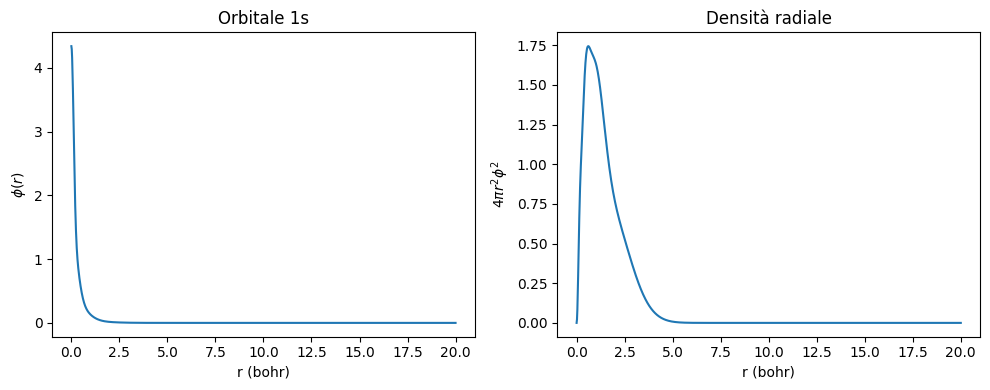

In [26]:
r  = np.linspace(0, 20, 1000) #in bohr units

N = (2*alpha/np.pi)**0.75                       # normaliz. factor of each basis
phi = sum(C[p] * N[p] * np.exp(-alpha[p] * r**2) for p in range(len(alpha)))

R = 4*np.pi*r**2*phi #radial part

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(r, phi)
ax[0].set_xlabel("r (bohr)")
ax[0].set_ylabel(r"$\phi(r)$")
ax[0].set_title("Orbitale 1s")

ax[1].plot(r, R)
ax[1].set_xlabel("r (bohr)")
ax[1].set_ylabel(r"$4\pi r^2 \phi^2$")
ax[1].set_title("Densità radiale")

plt.tight_layout()
plt.show()

